# COVID-19 in Canada — Trends and Vaccination Impact

**Question:** How did COVID-19 cases and deaths in Canada change over time, and did the share of cases that ended in death fall as vaccination coverage rose?

**Data:** Our World in Data (OWID) COVID-19 dataset, Canada only (cases and deaths from WHO, vaccinations from official Canadian sources). Saved as `data/canada_covid.csv`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.rcParams["figure.dpi"] = 110
df = pd.read_csv("../data/canada_covid.csv", parse_dates=["date"]).set_index("date")
print(df.shape, df.index.min().date(), "to", df.index.max().date())
df.tail(3)

(1674, 12) 2020-01-05 to 2024-08-04


,new_cases,new_cases_smoothed,new_deaths,new_deaths_smoothed,new_cases_smoothed_per_million,new_deaths_smoothed_per_million,hosp_patients,icu_patients,people_vaccinated_per_hundred,people_fully_vaccinated_per_hundred,total_boosters_per_hundred,population
date,,,,,,,,,,,,
2024-08-02,0.0,46.71,0.0,0.29,1.20,0.01,NaN,NaN,NaN,NaN,NaN,38454328
2024-08-03,0.0,46.71,0.0,0.29,1.20,0.01,NaN,NaN,NaN,NaN,NaN,38454328
2024-08-04,38.0,5.43,0.0,0.00,0.14,0.00,NaN,NaN,NaN,NaN,NaN,38454328


## 1. Turn the data into a weekly time series
Canada's counts in this source are reported **once a week** (other days show 0). Summing by week gives a clean series. Vaccination % is a running total, so we keep the last value of each week.

In [2]:
weekly = pd.DataFrame({
    "cases": df["new_cases"].resample("W-SUN").sum(),
    "deaths": df["new_deaths"].resample("W-SUN").sum(),
    "hospitalized": df["hosp_patients"].resample("W-SUN").mean(),
    "first_dose_pct": df["people_vaccinated_per_hundred"].resample("W-SUN").last().ffill(),
    "fully_vax_pct": df["people_fully_vaccinated_per_hundred"].resample("W-SUN").last().ffill(),
    "boosted_pct": df["total_boosters_per_hundred"].resample("W-SUN").last().ffill(),
}).fillna({"first_dose_pct": 0, "fully_vax_pct": 0, "boosted_pct": 0})
weekly = weekly.loc["2020-03-01":"2023-12-31"]
print(f"{len(weekly)} weeks; total cases {weekly['cases'].sum():,.0f}; total deaths {weekly['deaths'].sum():,.0f}")
weekly.describe().round(1)

201 weeks; total cases 4,774,227; total deaths 54,772


,cases,deaths,hospitalized,first_dose_pct,fully_vax_pct,boosted_pct
count,201.0,201.0,196.0,201.0,201.0,201.0
mean,23752.4,272.5,3604.9,58.8,51.9,36.8
std,36093.7,259.7,2204.0,38.5,37.6,36.6
min,6.0,0.0,268.9,0.0,0.0,0.0
25%,4945.0,96.0,1874.1,2.6,0.8,0.0
50%,15989.0,205.0,3463.5,84.0,78.3,39.8
75%,26963.0,332.0,5112.6,90.2,82.6,78.7
max,293833.0,1174.0,11160.9,90.4,82.6,89.2


## 2. Cases, deaths and vaccination over time

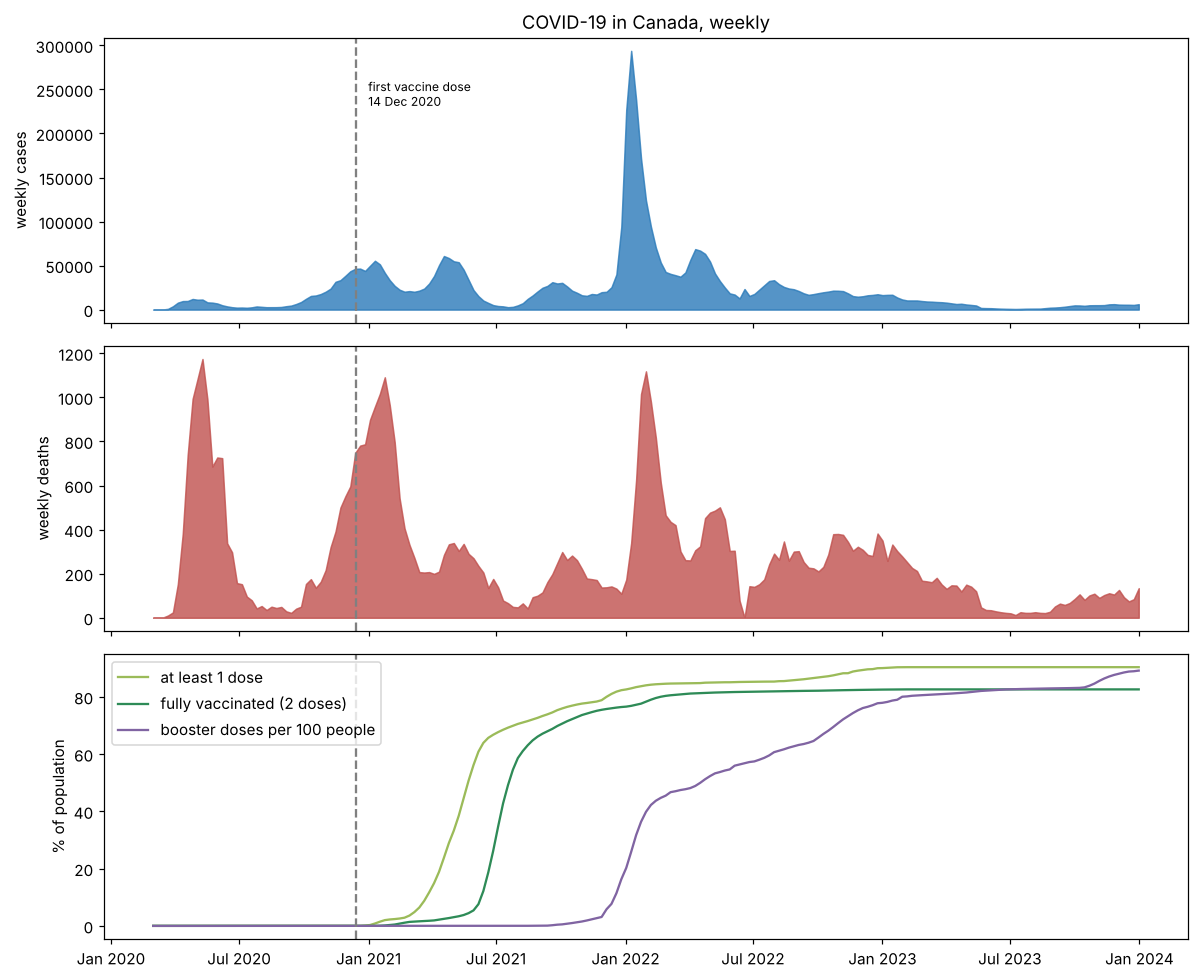

In [3]:
fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
axes[0].fill_between(weekly.index, weekly["cases"], color="#2a7ab9", alpha=.8); axes[0].set_ylabel("weekly cases")
axes[0].set_title("COVID-19 in Canada, weekly")
axes[1].fill_between(weekly.index, weekly["deaths"], color="#c0504d", alpha=.8); axes[1].set_ylabel("weekly deaths")
axes[2].plot(weekly.index, weekly["first_dose_pct"], label="at least 1 dose", color="#9bbb59")
axes[2].plot(weekly.index, weekly["fully_vax_pct"], label="fully vaccinated (2 doses)", color="#2e8b57")
axes[2].plot(weekly.index, weekly["boosted_pct"], label="booster doses per 100 people", color="#8064a2")
axes[2].set_ylabel("% of population"); axes[2].legend(loc="upper left")
for ax in axes: ax.axvline(pd.Timestamp("2020-12-14"), ls="--", color="grey")
axes[0].annotate("first vaccine dose\n14 Dec 2020", xy=(pd.Timestamp("2020-12-14"), axes[0].get_ylim()[1]*.75), xytext=(8, 0), textcoords="offset points", fontsize=8)
axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.tight_layout(); plt.savefig("../images/trends.png", bbox_inches="tight"); plt.show()

## 3. Deaths per 100 cases, by period
Deaths lag infections by a few weeks, so we compare each week's cases with deaths **3 weeks later** (a *lagged case fatality ratio*).

Two things about Canada's rollout shape how we read this:
- Long-term-care residents and the oldest age groups (where most deaths happened) were vaccinated **first**, from December 2020.
- Canada **delayed second doses** in spring 2021 to give more people a first dose, so "at least 1 dose" tracks real protection better than "fully vaccinated" for most of 2021.

Wave 1 (spring 2020) is shown separately: testing was very limited, so many mild cases were never counted and the ratio is inflated.

In [4]:
LAG_WEEKS = 3
weekly["deaths_lagged"] = weekly["deaths"].shift(-LAG_WEEKS)
periods = {
    "1. Wave 1 (limited testing)": ("2020-03-01", "2020-08-31"),
    "2. Wave 2, pre-vaccine": ("2020-09-01", "2020-12-13"),
    "3. Rollout to LTC + oldest": ("2020-12-14", "2021-02-28"),
    "4. Mass first doses": ("2021-03-01", "2021-05-31"),
    "5. Delta, high coverage": ("2021-07-01", "2021-11-30"),
    "6. Omicron + boosters": ("2021-12-01", "2022-06-30"),
}
rows = []
for name, (start, end) in periods.items():
    w = weekly.loc[start:end]
    rows.append({"period": name, "start": start, "end": end, "cases": w["cases"].sum(), "deaths (3 wk later)": w["deaths_lagged"].sum(),
                 "deaths per 100 cases": 100 * w["deaths_lagged"].sum() / w["cases"].sum(),
                 "1+ dose at end (%)": w["first_dose_pct"].iloc[-1]})
cfr = pd.DataFrame(rows).set_index("period")
cfr.round(2)

,start,end,cases,deaths (3 wk later),deaths per 100 cases,1+ dose at end (%)
period,,,,,,
1. Wave 1 (limited testing),2020-03-01,2020-08-31,127301.0,9166.0,7.20,0.00
"2. Wave 2, pre-vaccine",2020-09-01,2020-12-13,321529.0,6465.0,2.01,0.00
3. Rollout to LTC + oldest,2020-12-14,2021-02-28,412708.0,6790.0,1.65,3.60
4. Mass first doses,2021-03-01,2021-05-31,512726.0,3345.0,0.65,56.15
"5. Delta, high coverage",2021-07-01,2021-11-30,369870.0,3517.0,0.95,78.82
6. Omicron + boosters,2021-12-01,2022-06-30,2149013.0,12215.0,0.57,85.23


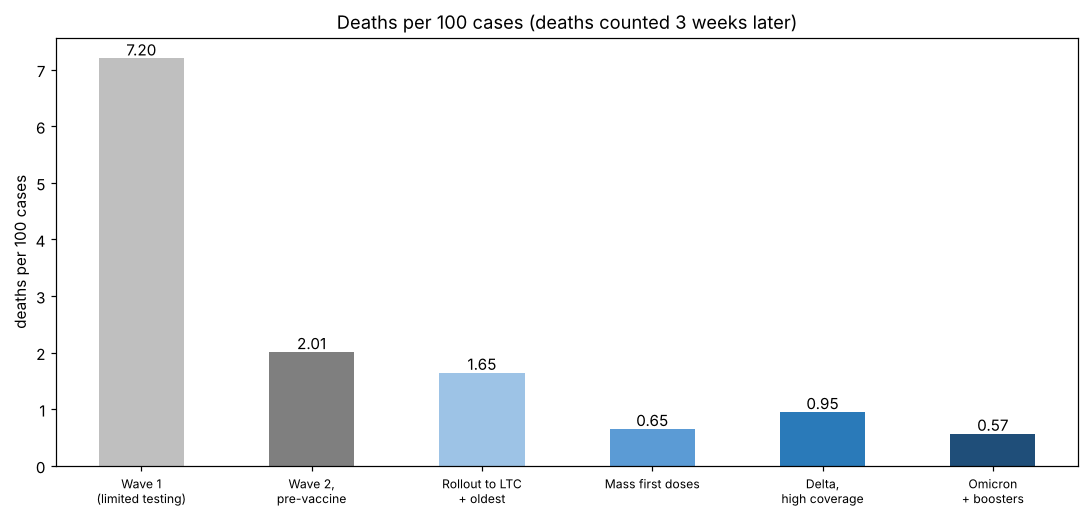

In [5]:
ax = cfr["deaths per 100 cases"].plot.bar(figsize=(10, 4.8), color=["#bfbfbf", "#7f7f7f", "#9dc3e6", "#5b9bd5", "#2a7ab9", "#1f4e79"], rot=0)
for i, v in enumerate(cfr["deaths per 100 cases"]): ax.text(i, v + 0.05, f"{v:.2f}", ha="center")
ax.set(title="Deaths per 100 cases (deaths counted 3 weeks later)", ylabel="deaths per 100 cases", xlabel="")
ax.set_xticklabels([p.split(". ")[1].replace(", ", ",\n").replace(" (", "\n(").replace(" + ", "\n+ ") for p in cfr.index], fontsize=8)
plt.tight_layout(); plt.savefig("../images/cfr_by_period.png", bbox_inches="tight"); plt.show()

## 4. Month by month: first-dose coverage vs deaths per case
Each dot is one month from September 2020 (wave 2, before vaccines) to November 2021. Spearman's rank correlation measures whether higher coverage goes with lower deaths per case, without assuming a straight line.

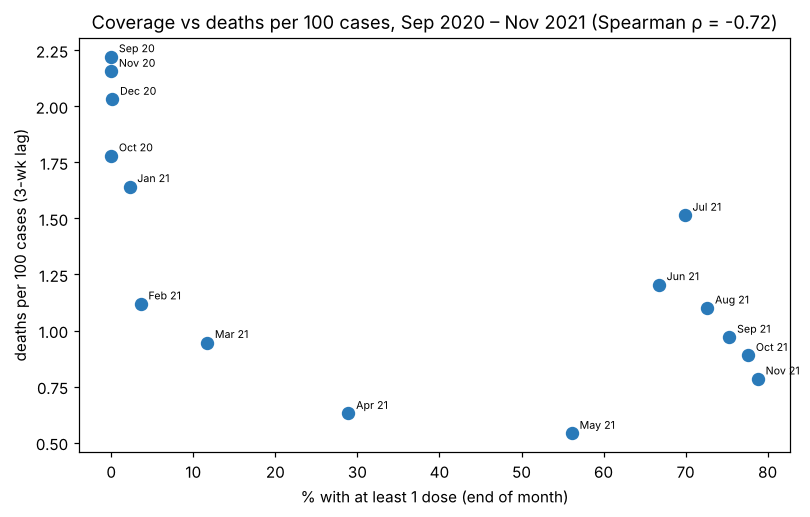

Spearman rho = -0.72


,cases,deaths_lagged,first_dose_pct,deaths_per_100_cases
date,,,,
2020-09-30,23146.0,514.0,0.00,2.22
2020-10-31,61276.0,1090.0,0.00,1.78
2020-11-30,147332.0,3176.0,0.00,2.16
2020-12-31,180177.0,3659.0,0.14,2.03
2021-01-31,231552.0,3801.0,2.24,1.64
2021-02-28,90754.0,1015.0,3.60,1.12
2021-03-31,95108.0,900.0,11.70,0.95
2021-04-30,207925.0,1310.0,28.91,0.63
2021-05-31,209693.0,1135.0,56.15,0.54


In [6]:
monthly = weekly.resample("ME").agg({"cases": "sum", "deaths_lagged": "sum", "first_dose_pct": "last"})
monthly["deaths_per_100_cases"] = 100 * monthly["deaths_lagged"] / monthly["cases"]
mm = monthly.loc["2020-09":"2021-11"]
r = mm[["first_dose_pct", "deaths_per_100_cases"]].corr(method="spearman").iloc[0, 1]
ax = mm.plot.scatter(x="first_dose_pct", y="deaths_per_100_cases", s=60, figsize=(7.5, 4.8), color="#2a7ab9")
for d, row in mm.iterrows(): ax.annotate(d.strftime("%b %y"), (row["first_dose_pct"], row["deaths_per_100_cases"]), xytext=(5, 3), textcoords="offset points", fontsize=7)
ax.set(title=f"Coverage vs deaths per 100 cases, Sep 2020 – Nov 2021 (Spearman ρ = {r:.2f})", xlabel="% with at least 1 dose (end of month)", ylabel="deaths per 100 cases (3-wk lag)")
plt.tight_layout(); plt.savefig("../images/coverage_vs_cfr.png", bbox_inches="tight"); plt.show()
print(f"Spearman rho = {r:.2f}")
mm.round(2)

## 5. Takeaways
Numbers come from the period table and chart above.
- In wave 2, before vaccines, about **2.0 of every 100** reported cases were followed by a death three weeks later.
- Once vaccines reached long-term care and older adults, this fell to **1.65**, and during mass first doses in spring 2021 to **0.65**, about a **two-thirds drop** from wave 2, even though spring 2021 had *more* cases than wave 2.
- The ratio rose slightly in the Delta wave (**0.95**), a more severe variant, but stayed far below pre-vaccine levels with ~79% of people having at least one dose.
- Month by month, higher first-dose coverage went with fewer deaths per case (**Spearman ρ ≈ −0.72**).
- Omicron (**0.57**) is hard to compare: a milder variant, past infections, and restricted testing from January 2022 all changed at once.
- Wave 1's very high ratio (**7.2**) mostly reflects how few cases were detected and the outbreaks in long-term care, not just how deadly the virus was.

**Limitations:** this is observational, national-level data, so it shows association rather than proof that vaccines caused the drop. Treatments improved, variants changed, and testing changed over the same period. A stronger analysis would compare age-specific death rates of vaccinated and unvaccinated people using provincial or PHAC data.

In [7]:
cfr.round(3).to_csv("../images/cfr_by_period.csv")